#Import dan load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sales     = pd.read_csv("ecommerce_sales_customer_analytics_150k.csv")
items     = pd.read_csv("order_items.csv")
customers = pd.read_csv("customer_master.csv")
products  = pd.read_csv("product_catalog.csv")
stats     = pd.read_csv("dataset_statistics.csv")

#Data Understanding

###1.0 Overview

In [ ]:
tables = {"sales": sales, "items": items, "customers": customers, "products": products, "stats": stats}
overview = pd.DataFrame({
    "rows": [df.shape[0] for df in tables.values()],
    "columns": [df.shape[1] for df in tables.values()],
    "missing_cells": [df.isnull().sum().sum() for df in tables.values()],
    "duplicate_rows": [df.duplicated().sum() for df in tables.values()],
}, index=tables.keys())
overview

,rows,columns,missing_cells,duplicate_rows
sales,138116,46,573828,0
items,397569,12,0,0
customers,25000,11,0,0
products,1175,9,0,0
stats,1,11,0,0


###1.1 sales (transaksi per order)

In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

In [ ]:
# customer_name, customer_city, customer_postal_code are hidden (personal data)
sales.drop(columns=["customer_name", "customer_city", "customer_postal_code"]).head(3).T

,0,1,2
order_id,ORD-301242,ORD-773460,ORD-449374
order_date,2023-11-06,2025-12-24,2021-07-05
order_time,16:37:47,01:22:36,14:24:21
order_status,Completed,Completed,Completed
sales_channel,Mobile App,Website,Mobile App
customer_id,CUST-003102,CUST-003124,CUST-012496
customer_age,55,26,69
gender,Male,Male,Female
customer_segment,Consumer,Premium,Premium
customer_type,Loyal,Loyal,Loyal


In [ ]:
missing = sales.isnull().sum()
missing[missing > 0]

,0
delivery_days,24557
estimated_delivery_days,24557
return_status,128654
return_reason,128654
customer_rating,24557
review_sentiment,24557
customer_review,24557
campaign_name,83233
coupon_code,110502


In [ ]:
sales[["quantity", "gross_sales", "discount_amount", "tax_amount", "shipping_cost",
       "net_sales", "product_cost", "profit"]].describe()

,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit
count,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000
mean,5.615244,1375.384176,237.621614,122.462933,22.278080,1282.503575,708.903449,551.322046
std,3.371289,1291.009554,378.779459,140.939368,16.022739,1169.274669,730.044970,516.300936
min,1.000000,6.310000,0.000000,0.340000,0.000000,5.800000,1.970000,-1281.590000
25%,3.000000,458.920000,26.327500,34.650000,9.820000,448.200000,207.667500,190.757500
50%,5.000000,995.730000,103.285000,77.010000,19.190000,950.760000,478.955000,408.395000
75%,8.000000,1871.200000,277.125000,156.200000,30.750000,1744.582500,953.762500,752.845000
max,24.000000,16051.190000,6759.020000,2091.520000,149.520000,16218.000000,9963.410000,7083.680000


In [ ]:
for col in ["order_status", "sales_channel", "customer_segment", "customer_type", "customer_country",
            "payment_method", "payment_status", "marketing_channel", "campaign_name"]:
    print(col, "->", sales[col].nunique(), "values")
    print(sales[col].value_counts(dropna=False).head(6), "\n")

order_status -> 4 values
order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64 

sales_channel -> 4 values
sales_channel
Mobile App      55318
Website         48237
Marketplace     20698
Social Media    13863
Name: count, dtype: int64 

customer_segment -> 4 values
customer_segment
Consumer    75636
Premium     34746
VIP         13957
Business    13777
Name: count, dtype: int64 

customer_type -> 3 values
customer_type
Loyal        129447
Returning      8335
New             334
Name: count, dtype: int64 

customer_country -> 7 values
customer_country
USA          82600
UK           20235
Germany      11593
Canada        7015
Australia     6794
India         5707
Name: count, dtype: int64 

payment_method -> 7 values
payment_method
Credit Card          41460
Debit Card           27635
PayPal               20750
Digital Wallet       16382
Cash on Delivery     13863
Buy Now Pay Later    11061
Name: count, dtype: int64 

paym

###1.2 items (satu baris per produk dalam order)

In [ ]:
items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397569 entries, 0 to 397568
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             397569 non-null  object 
 1   product_id           397569 non-null  object 
 2   quantity             397569 non-null  int64  
 3   unit_price           397569 non-null  float64
 4   discount_percentage  397569 non-null  float64
 5   discount_amount      397569 non-null  float64
 6   gross_sales          397569 non-null  float64
 7   tax_amount           397569 non-null  float64
 8   shipping_cost        397569 non-null  float64
 9   net_sales            397569 non-null  float64
 10  product_cost         397569 non-null  float64
 11  profit               397569 non-null  float64
dtypes: float64(9), int64(1), object(2)
memory usage: 36.4+ MB


In [ ]:
items.head(3)

,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84


In [ ]:
items[["quantity", "unit_price", "discount_percentage", "discount_amount", "gross_sales",
       "tax_amount", "shipping_cost", "net_sales", "product_cost", "profit"]].describe()

,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
count,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000
mean,2.118792,245.189134,0.147059,89.667873,519.013550,46.183642,8.409010,483.938328,267.520046,208.009273
std,1.196276,251.035134,0.129986,190.637796,676.800478,71.072019,6.777155,615.430188,394.773555,266.477677
min,1.000000,6.310000,0.000000,0.000000,6.310000,0.260000,0.000000,5.350000,1.970000,-1260.280000
25%,1.000000,74.360000,0.048137,5.940000,122.000000,9.560000,3.370000,124.280000,52.960000,53.730000
50%,2.000000,164.970000,0.124253,26.340000,280.190000,22.550000,5.870000,271.100000,127.100000,121.660000
75%,3.000000,310.790000,0.199499,86.030000,643.560000,52.340000,12.460000,595.240000,314.310000,259.660000
max,5.000000,1482.950000,0.600000,3857.670000,7414.750000,1482.950000,36.460000,8897.700000,4968.150000,4045.100000


###1.3 customers (profil customer)

In [ ]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  object 
 1   customer_name              25000 non-null  object 
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  object 
 4   customer_segment           25000 non-null  object 
 5   customer_city              25000 non-null  object 
 6   customer_state             25000 non-null  object 
 7   customer_country           25000 non-null  object 
 8   region                     25000 non-null  object 
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), object(8)
memory usage: 2.1+ MB


In [ ]:
# customer_name, customer_city, customer_postal_code are hidden (personal data)
customers.drop(columns=["customer_name", "customer_city", "customer_postal_code"]).head(3)

,customer_id,customer_age,gender,customer_segment,customer_state,customer_country,region,customer_acquisition_cost
0,CUST-000001,54,Female,Consumer,Dubai,UAE,South,13.58
1,CUST-000002,61,Male,Consumer,Lower Saxony,Germany,North,27.45
2,CUST-000003,47,Male,Consumer,North Rhine,Germany,West,31.53


In [ ]:
display(customers[["customer_age", "customer_acquisition_cost"]].describe())
print(customers["customer_segment"].value_counts(), "\n")
print(customers["customer_country"].value_counts(), "\n")
print(customers["gender"].value_counts())

,customer_age,customer_acquisition_cost
count,25000.000000,25000.000000
mean,45.907840,42.159750
std,16.454286,21.692648
min,18.000000,5.010000
25%,32.000000,23.297500
50%,46.000000,41.980000
75%,60.000000,61.130000
max,74.000000,79.990000


customer_segment
Consumer    13638
Premium      6301
VIP          2542
Business     2519
Name: count, dtype: int64 

customer_country
USA          14925
UK            3701
Germany       2046
Canada        1279
Australia     1233
India         1041
UAE            775
Name: count, dtype: int64 

gender
Female        12048
Male          11976
Non-Binary      976
Name: count, dtype: int64


###1.4 products (katalog produk)

In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1175 entries, 0 to 1174
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1175 non-null   object 
 1   product_name         1175 non-null   object 
 2   product_category     1175 non-null   object 
 3   product_subcategory  1175 non-null   object 
 4   brand                1175 non-null   object 
 5   supplier             1175 non-null   object 
 6   unit_price           1175 non-null   float64
 7   product_cost         1175 non-null   float64
 8   product_rating       1175 non-null   float64
dtypes: float64(3), object(6)
memory usage: 82.7+ KB


In [ ]:
products.head(3)

,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9


In [ ]:
display(products[["unit_price", "product_cost", "product_rating"]].describe())
print("Categories:", products["product_category"].nunique(), "| Subcategories:", products["product_subcategory"].nunique(),
      "| Brands:", products["brand"].nunique(), "| Suppliers:", products["supplier"].nunique(), "\n")
print(products["product_category"].value_counts())

,unit_price,product_cost,product_rating
count,1175.000000,1175.000000,1175.000000
mean,245.524400,126.536826,3.683064
std,251.267683,150.131833,0.698046
min,6.310000,1.970000,2.500000
25%,74.710000,29.565000,3.100000
50%,165.420000,74.540000,3.700000
75%,311.295000,153.045000,4.300000
max,1482.950000,993.630000,4.900000


Categories: 15 | Subcategories: 117 | Brands: 144 | Suppliers: 10 

product_category
Sports & Outdoors         91
Books & Media             87
Health & Wellness         86
Beauty & Personal Care    83
Automotive                81
Office Supplies           80
Electronics               78
Home Appliances           78
Grocery                   78
Toys & Games              77
Baby & Kids               75
Pet Supplies              74
Home & Kitchen            70
Jewelry                   69
Fashion                   68
Name: count, dtype: int64


###1.5 stats

In [ ]:
stats.T

,0
Total Transactions,138116
Total Columns,46
Total Customers,24911
Total Products Used,138116
Date Range,2021-01-01 to 2025-12-31
Total Revenue,"$177,134,263.74"
Total Profit,"$76,146,395.76"
Average Order Value,"$1,282.50"
Average Rating,3.68
Return Rate,6.85%


#####Catatan untuk interpretasi: nilai revenue, profit, dan rate di file ini disimpan sebagai teks. File ini dipakai sebagai pembanding, bukan sumber perhitungan.

#Cek Kualitas Data dan Eksplorasi

###2.1 Key dan relasi antar dataset

In [ ]:
print("sales     - order_id unique      :", sales["order_id"].is_unique)
print("customers - customer_id unique   :", customers["customer_id"].is_unique)
print("products  - product_id unique    :", products["product_id"].is_unique)
print("items     - total rows           :", len(items))
print("items     - unique order+product :", len(items.drop_duplicates(["order_id", "product_id"])))

sales     - order_id unique      : True
customers - customer_id unique   : True
products  - product_id unique    : True
items     - total rows           : 397569
items     - unique order+product : 397482


In [ ]:
print("Items without order     :", (~items["order_id"].isin(sales["order_id"])).sum())
print("Items without product   :", (~items["product_id"].isin(products["product_id"])).sum())
print("Orders without customer :", (~sales["customer_id"].isin(customers["customer_id"])).sum())
print("Orders without items    :", (~sales["order_id"].isin(items["order_id"])).sum())
print("Customers without orders:", (~customers["customer_id"].isin(sales["customer_id"])).sum())
print("Products never sold     :", (~products["product_id"].isin(items["product_id"])).sum())

Items without order     : 0
Items without product   : 0
Orders without customer : 0
Orders without items    : 0
Customers without orders: 89
Products never sold     : 0


###2.2 Apakah angka antar dataset cocok?

####apakah net_sales dan profit sudah memuat pajak?

In [ ]:
for name, df in [("sales", sales), ("items", items)]:
    net_ok    = ((df["gross_sales"] - df["discount_amount"] + df["tax_amount"] + df["shipping_cost"]) - df["net_sales"]).abs().max() < 0.02
    profit_ok = ((df["gross_sales"] - df["discount_amount"] + df["tax_amount"] - df["product_cost"]) - df["profit"]).abs().max() < 0.02
    print(name, "| net_sales = gross - discount + tax + shipping:", net_ok, "| profit = gross - discount + tax - cost:", profit_ok)
print("Tax as % of reported profit (sales):", round(sales["tax_amount"].sum() / sales["profit"].sum() * 100, 1))

sales | net_sales = gross - discount + tax + shipping: True | profit = gross - discount + tax - cost: True
items | net_sales = gross - discount + tax + shipping: True | profit = gross - discount + tax - cost: True
Tax as % of reported profit (sales): 22.2


####items vs katalog produk

In [ ]:
chk = items.merge(products[["product_id", "unit_price", "product_cost"]], on="product_id", suffixes=("", "_catalog"))
print("Max unit_price difference vs catalog :", round((chk["unit_price"] - chk["unit_price_catalog"]).abs().max(), 4))
print("Max cost difference vs catalog x qty :", round((chk["product_cost"] - chk["product_cost_catalog"] * chk["quantity"]).abs().max(), 4))

Max unit_price difference vs catalog : 0.0
Max cost difference vs catalog x qty : 0.0


####total order (sales) vs jumlah item

In [ ]:
items_total = items.groupby("order_id")["gross_sales"].sum()
diff = sales.set_index("order_id")["gross_sales"] - items_total
print("Orders where items total != order total:", (diff.abs() > 0.05).sum())
print("Gross sales | sales table:", round(sales["gross_sales"].sum()), "| items table:", round(items["gross_sales"].sum()))

Orders where items total != order total: 11226
Gross sales | sales table: 189962561 | items table: 206343698


####file stats vs hitungan dari data

In [ ]:
s = stats.iloc[0]
compare = pd.DataFrame({
    "stats_file": [s["Total Transactions"], s["Total Customers"], s["Total Products Used"], s["Total Revenue"],
                   s["Total Profit"], s["Average Order Value"], s["Return Rate"], s["Cancellation Rate"]],
    "from_data":  [len(sales), sales["customer_id"].nunique(), items["product_id"].nunique(),
                   f"${sales['net_sales'].sum():,.2f}", f"${sales['profit'].sum():,.2f}", f"${sales['net_sales'].mean():,.2f}",
                   f"{sales['return_status'].notna().mean() * 100:.2f}%", f"{(sales['order_status'] == 'Cancelled').mean() * 100:.2f}%"]},
    index=["Total Transactions", "Total Customers", "Total Products Used", "Total Revenue", "Total Profit",
           "Average Order Value", "Return Rate", "Cancellation Rate"])
compare

,stats_file,from_data
Total Transactions,138116,138116
Total Customers,24911,24911
Total Products Used,138116,1175
Total Revenue,"$177,134,263.74","$177,134,263.74"
Total Profit,"$76,146,395.76","$76,146,395.76"
Average Order Value,"$1,282.50","$1,282.50"
Return Rate,6.85%,6.85%
Cancellation Rate,6.08%,6.08%


###2.3 Menyiapkan penjualan valid

#####Hanya order berstatus Completed dianggap penjualan valid. Revenue dihitung tanpa pajak dan ongkir (gross_sales - discount_amount), dan profit = revenue - product_cost.

In [ ]:
completed = sales[sales["order_status"] == "Completed"].copy()
completed["order_date"]    = pd.to_datetime(completed["order_date"])
completed["net_revenue"]   = completed["gross_sales"] - completed["discount_amount"]
completed["gross_profit"]  = completed["net_revenue"] - completed["product_cost"]
completed["discount_rate"] = completed["discount_amount"] / completed["gross_sales"]
print(completed.shape)

(113559, 49)


###2.4 sales: grafik

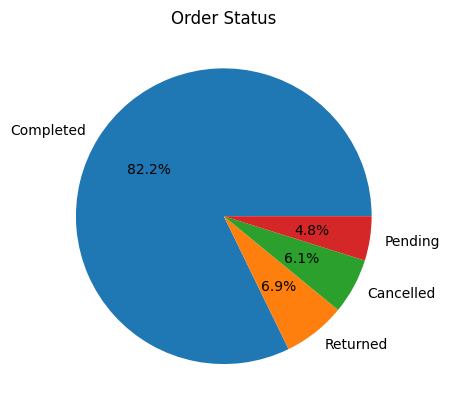

In [ ]:
sales["order_status"].value_counts().plot.pie(autopct="%.1f%%")
plt.title("Order Status")
plt.ylabel("")
plt.show()

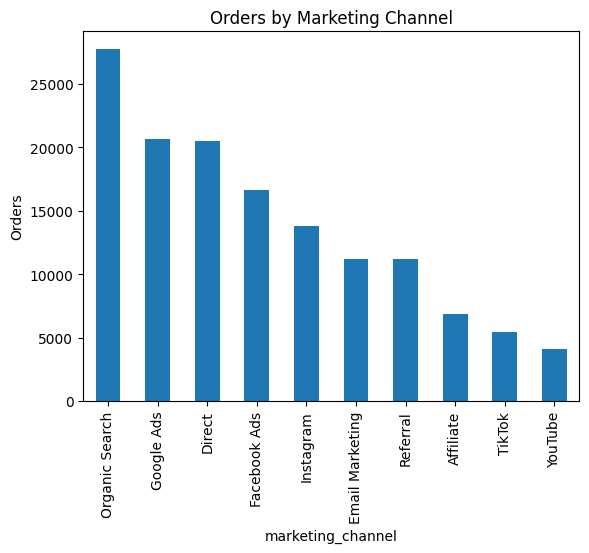

In [ ]:
sales["marketing_channel"].value_counts().plot.bar()
plt.title("Orders by Marketing Channel")
plt.ylabel("Orders")
plt.show()

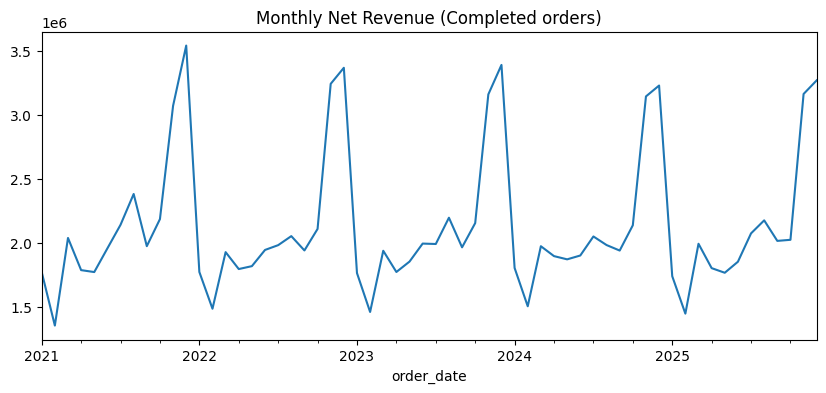

In [ ]:
monthly = completed.groupby(completed["order_date"].dt.to_period("M"))["net_revenue"].sum()
monthly.plot(figsize=(10, 4))
plt.title("Monthly Net Revenue (Completed orders)")
plt.show()

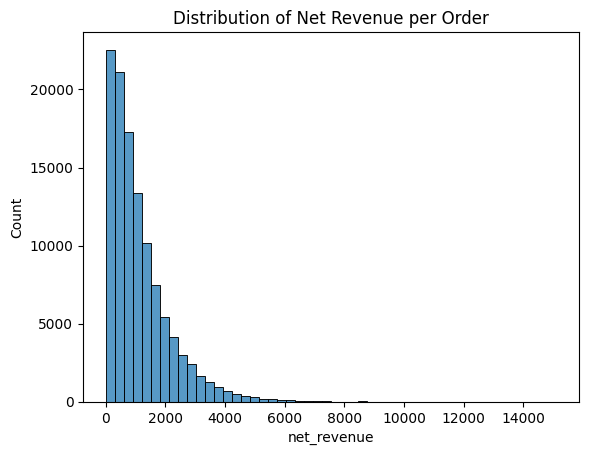

In [ ]:
sns.histplot(completed["net_revenue"], bins=50)
plt.title("Distribution of Net Revenue per Order")
plt.show()

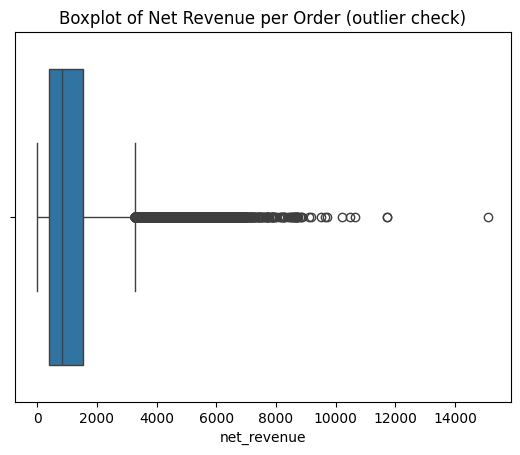

In [ ]:
sns.boxplot(x=completed["net_revenue"])
plt.title("Boxplot of Net Revenue per Order (outlier check)")
plt.show()

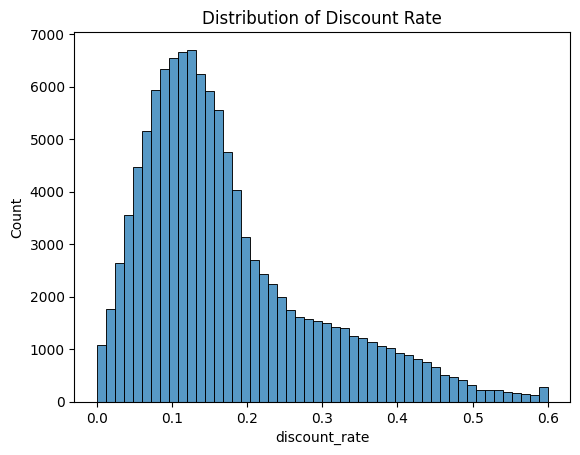

In [ ]:
sns.histplot(completed["discount_rate"], bins=50)
plt.title("Distribution of Discount Rate")
plt.show()

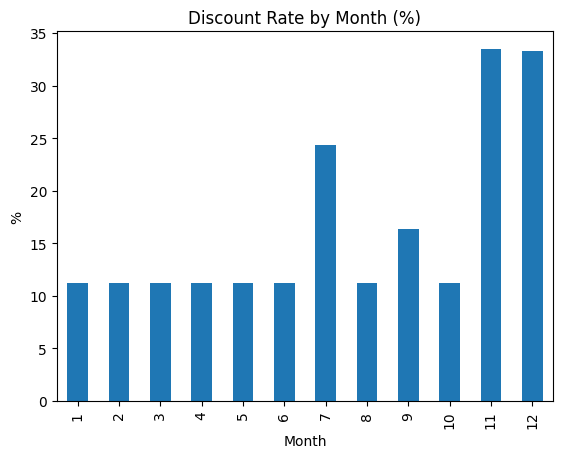

In [ ]:
m = completed.groupby(completed["order_date"].dt.month)[["discount_amount", "gross_sales"]].sum()
(m["discount_amount"] / m["gross_sales"] * 100).plot.bar()
plt.title("Discount Rate by Month (%)")
plt.xlabel("Month")
plt.ylabel("%")
plt.show()

###2.5 items: grafik

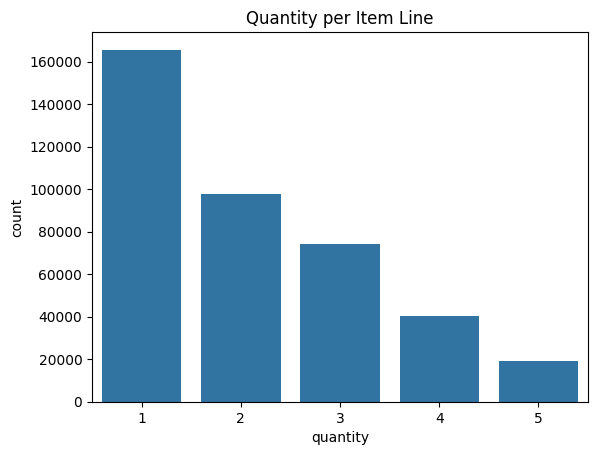

In [ ]:
sns.countplot(x=items["quantity"])
plt.title("Quantity per Item Line")
plt.show()

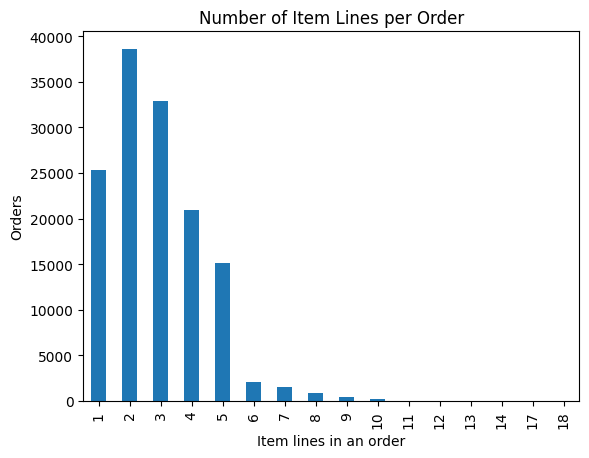

In [ ]:
items.groupby("order_id").size().value_counts().sort_index().plot.bar()
plt.title("Number of Item Lines per Order")
plt.xlabel("Item lines in an order")
plt.ylabel("Orders")
plt.show()

###2.6 customers: grafik

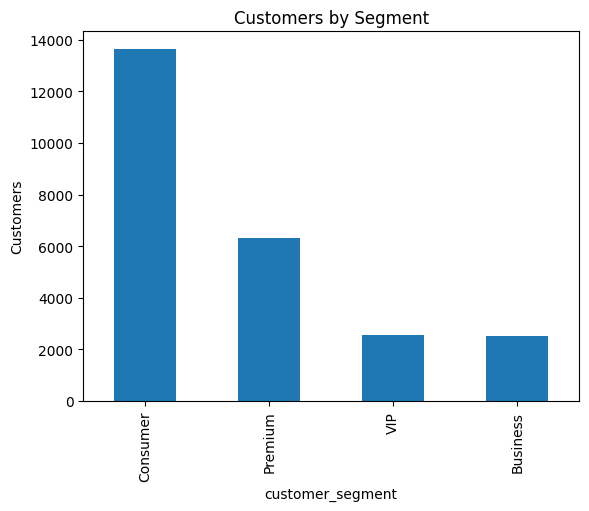

In [ ]:
customers["customer_segment"].value_counts().plot.bar()
plt.title("Customers by Segment")
plt.ylabel("Customers")
plt.show()

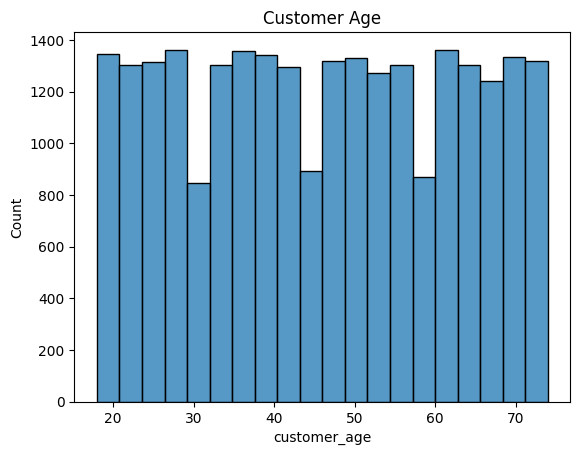

In [ ]:
sns.histplot(customers["customer_age"], bins=20)
plt.title("Customer Age")
plt.show()

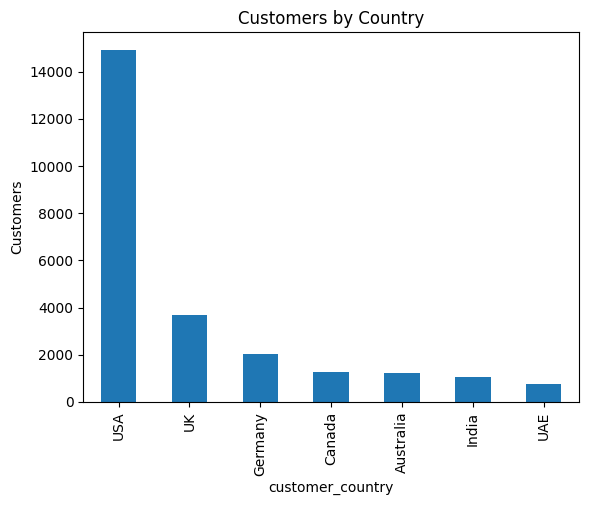

In [ ]:
customers["customer_country"].value_counts().plot.bar()
plt.title("Customers by Country")
plt.ylabel("Customers")
plt.show()

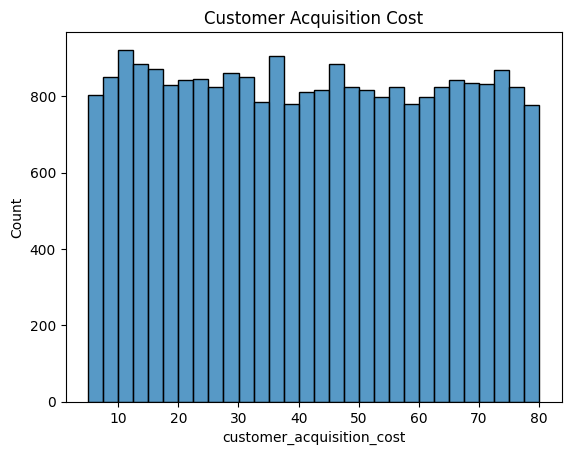

In [ ]:
sns.histplot(customers["customer_acquisition_cost"], bins=30)
plt.title("Customer Acquisition Cost")
plt.show()

###2.7 products: grafik

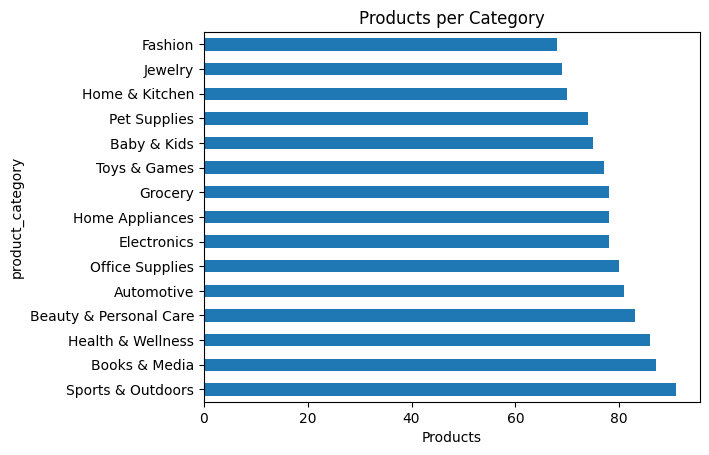

In [ ]:
products["product_category"].value_counts().plot.barh()
plt.title("Products per Category")
plt.xlabel("Products")
plt.show()

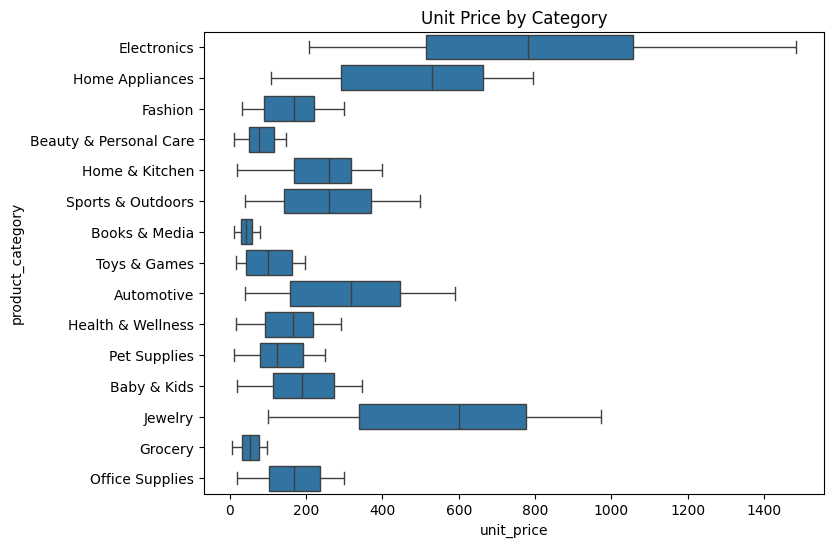

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=products, x="unit_price", y="product_category")
plt.title("Unit Price by Category")
plt.show()

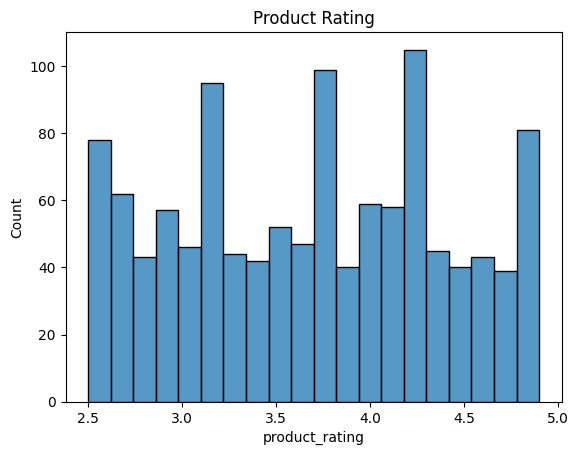

In [ ]:
sns.histplot(products["product_rating"], bins=20)
plt.title("Product Rating")
plt.show()

###2.8 Gambaran awal pertanyaan bisnis

####revenue, profit, dan margin per channel

In [ ]:
by_channel = completed.groupby("marketing_channel").agg(revenue=("net_revenue", "sum"), profit=("gross_profit", "sum"))
by_channel["margin_%"] = by_channel["profit"] / by_channel["revenue"] * 100
by_channel.sort_values("revenue", ascending=False).round(1)

,revenue,profit,margin_%
marketing_channel,,,
Organic Search,25846618.3,9292881.8,36.0
Google Ads,19306794.8,6889560.9,35.7
Direct,18807298.1,6813695.9,36.2
Facebook Ads,15304898.8,5515550.3,36.0
Instagram,12729552.7,4561840.5,35.8
Email Marketing,10496154.8,3762836.2,35.8
Referral,10265408.4,3697769.8,36.0
Affiliate,6382110.4,2309788.1,36.2
TikTok,4988774.3,1794458.3,36.0


####revenue, profit, dan margin per segmen customer

In [ ]:
by_segment = completed.groupby("customer_segment").agg(revenue=("net_revenue", "sum"), profit=("gross_profit", "sum"))
by_segment["margin_%"] = by_segment["profit"] / by_segment["revenue"] * 100
by_segment.round(1)

,revenue,profit,margin_%
customer_segment,,,
Business,12793300.4,4757276.4,37.2
Consumer,70168672.3,26308999.7,37.5
Premium,31935421.0,10601370.0,33.2
VIP,13009612.8,4331081.5,33.3


#Data Cleaning dan Feature Engineering

###3.1 Salinan kerja dan pengecekan teks

In [ ]:
# Work on copies, the original data stays untouched
sales_clean     = sales.copy()
items_clean     = items.copy()
customers_clean = customers.copy()
products_clean  = products.copy()

In [ ]:
# Quick check: extra spaces in text columns
for name, df in [("sales", sales_clean), ("items", items_clean), ("customers", customers_clean), ("products", products_clean)]:
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    bad = [c for c in text_cols if df[c].dropna().ne(df[c].dropna().str.strip()).any()]
    print(name, "-> columns with extra spaces:", bad)

sales -> columns with extra spaces: []
items -> columns with extra spaces: []
customers -> columns with extra spaces: []
products -> columns with extra spaces: []


###3.2 Menghapus data pribadi dan mengganti nama kolom

In [ ]:
# Remove personal data
sales_clean     = sales_clean.drop(columns=["customer_name", "customer_city", "customer_postal_code", "customer_review"])
customers_clean = customers_clean.drop(columns=["customer_name", "customer_city", "customer_postal_code"])
print(sales_clean.shape, customers_clean.shape)

(138116, 42) (25000, 8)


In [ ]:
# Rename columns that are misleading (they include tax, or come from data we cannot verify)
sales_clean = sales_clean.rename(columns={
    "net_sales": "invoice_total",
    "profit": "reported_profit",
    "profit_margin_percentage": "reported_margin_pct",
    "customer_lifetime_value": "reported_clv",
    "customer_order_count": "reported_order_count",
    "is_repeat_customer": "reported_is_repeat",
    "customer_type": "reported_customer_type"})
items_clean = items_clean.rename(columns={"net_sales": "invoice_total", "profit": "reported_profit"})
print(list(sales_clean.columns[-12:]))

['quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'invoice_total', 'product_cost', 'reported_profit', 'reported_margin_pct', 'reported_clv', 'reported_is_repeat', 'reported_order_count']


###3.3 Kolom baru di sales

In [ ]:
# Date columns and new time columns
sales_clean["order_date"] = pd.to_datetime(sales_clean["order_date"])
sales_clean["year"]  = sales_clean["order_date"].dt.year
sales_clean["month"] = sales_clean["order_date"].dt.month

# Discount season: months with deeper discounts (from the discount-by-month chart)
season = {7: "Medium", 9: "Light", 11: "Heavy", 12: "Heavy"}
sales_clean["discount_season"] = sales_clean["month"].map(season).fillna("Regular")
sales_clean["discount_season"].value_counts()

,count
discount_season,
Regular,83426
Heavy,33628
Light,10855
Medium,10207


In [ ]:
# Revenue and profit without tax and shipping
sales_clean["net_revenue"]   = sales_clean["gross_sales"] - sales_clean["discount_amount"]
sales_clean["gross_profit"]  = sales_clean["net_revenue"] - sales_clean["product_cost"]
sales_clean["discount_rate"] = sales_clean["discount_amount"] / sales_clean["gross_sales"]

In [ ]:
# Flags (1 = yes, 0 = no)
sales_clean["is_valid_sale"]   = (sales_clean["order_status"] == "Completed").astype(int)
sales_clean["is_returned"]     = (sales_clean["order_status"] == "Returned").astype(int)
sales_clean["has_coupon"]      = sales_clean["coupon_code"].notnull().astype(int)
sales_clean["payment_pending"] = ((sales_clean["is_valid_sale"] == 1) & (sales_clean["payment_status"] == "Pending")).astype(int)
sales_clean["reported_is_repeat"] = sales_clean["reported_is_repeat"].astype(int)

In [ ]:
# Campaign group: real campaign, default placeholder, or no campaign recorded
sales_clean["campaign_group"] = np.where(sales_clean["campaign_name"].isnull(), "Not tagged",
                                np.where(sales_clean["campaign_name"] == "Default_Campaign", "Default", "Named"))
sales_clean["campaign_group"].value_counts()

,count
campaign_group,
Not tagged,83233
Named,31894
Default,22989


###3.4 Tabel items, customers, dan data kosong

In [ ]:
# Mark which item lines are included in the order total of the sales table
items_clean["line_id"]  = range(1, len(items_clean) + 1)
items_clean["line_seq"] = items_clean.groupby("order_id").cumcount() + 1
items_clean["cum_gross"] = items_clean.groupby("order_id")["gross_sales"].cumsum()

order_gross = sales_clean.set_index("order_id")["gross_sales"]
items_clean["order_gross"] = items_clean["order_id"].map(order_gross)

# last line whose running total equals the order total in sales
matched = items_clean[(items_clean["cum_gross"] - items_clean["order_gross"]).abs() <= 0.02]
last_line = matched.groupby("order_id")["line_seq"].max()
items_clean["is_reconciled_line"] = (items_clean["line_seq"] <= items_clean["order_id"].map(last_line)).astype(int)
items_clean = items_clean.drop(columns=["line_seq", "cum_gross", "order_gross"])
items_clean["is_reconciled_line"].value_counts()

,count
is_reconciled_line,
1,365978
0,31591


In [ ]:
# Customer age group
customers_clean["age_band"] = pd.cut(customers_clean["customer_age"], bins=[17, 29, 39, 49, 59, 74],
                                     labels=["18-29", "30-39", "40-49", "50-59", "60-74"])
customers_clean["age_band"].value_counts().sort_index()

,count
age_band,
18-29,5322
30-39,4387
40-49,4415
50-59,4324
60-74,6552


In [ ]:
# Missing values are NOT filled: they have meaning (no return, no coupon, order not delivered)
missing = sales_clean.isnull().sum()
missing[missing > 0]

,0
delivery_days,24557
estimated_delivery_days,24557
return_status,128654
return_reason,128654
customer_rating,24557
review_sentiment,24557
campaign_name,83233
coupon_code,110502


#Validasi dan Ekspor

###4.1 Validasi hasil cleaning

In [ ]:
# Row counts: clean vs original
check = pd.DataFrame({
    "original": [len(sales), len(items), len(customers), len(products)],
    "clean":    [len(sales_clean), len(items_clean), len(customers_clean), len(products_clean)]},
    index=["sales", "items", "customers", "products"])
check["same"] = check["original"] == check["clean"]
check

,original,clean,same
sales,138116,138116,True
items,397569,397569,True
customers,25000,25000,True
products,1175,1175,True


In [ ]:
# Valid sales revenue: clean table vs direct calculation from original data
orig = sales[sales["order_status"] == "Completed"]
print("Revenue from original :", round((orig["gross_sales"] - orig["discount_amount"]).sum(), 2))
print("Revenue from clean    :", round(sales_clean.loc[sales_clean["is_valid_sale"] == 1, "net_revenue"].sum(), 2))
print("Valid orders          :", sales_clean["is_valid_sale"].sum())

Revenue from original : 127907006.57
Revenue from clean    : 127907006.57
Valid orders          : 113559


In [ ]:
# Do the reconciled item lines now match the sales table?
rec = items_clean[items_clean["is_reconciled_line"] == 1]
print("Reconciled lines:", len(rec), "| extra lines:", len(items_clean) - len(rec))
print("Gross sales | sales table:", round(sales_clean["gross_sales"].sum(), 2), "| reconciled items:", round(rec["gross_sales"].sum(), 2))
print("Orders still different:", ((rec.groupby("order_id")["gross_sales"].sum() - order_gross).abs() > 0.05).sum())

Reconciled lines: 365978 | extra lines: 31591
Gross sales | sales table: 189962560.88 | reconciled items: 189962560.88
Orders still different: 0


In [ ]:
# No personal data and no missing keys
pii = ["customer_name", "customer_city", "customer_postal_code", "customer_review"]
for name, df in [("sales", sales_clean), ("customers", customers_clean)]:
    print(name, "personal columns left:", [c for c in pii if c in df.columns])
print("Missing keys:", sales_clean[["order_id", "customer_id"]].isnull().sum().sum(),
      items_clean[["order_id", "product_id"]].isnull().sum().sum(),
      customers_clean["customer_id"].isnull().sum(), products_clean["product_id"].isnull().sum())

sales personal columns left: []
customers personal columns left: []
Missing keys: 0 0 0 0


In [ ]:
# Preview of the final tables
sales_clean[["order_id", "order_date", "order_status", "marketing_channel", "gross_sales", "discount_amount",
             "net_revenue", "gross_profit", "discount_season", "is_valid_sale", "campaign_group"]].head()

,order_id,order_date,order_status,marketing_channel,gross_sales,discount_amount,net_revenue,gross_profit,discount_season,is_valid_sale,campaign_group
0,ORD-301242,2023-11-06,Completed,Direct,1350.19,477.89,872.30,283.97,Heavy,1,Default
1,ORD-773460,2025-12-24,Completed,Direct,3144.64,1456.06,1688.58,-343.30,Heavy,1,Default
2,ORD-449374,2021-07-05,Completed,YouTube,522.81,97.30,425.51,167.78,Medium,1,Not tagged
3,ORD-567636,2023-01-21,Completed,Email Marketing,544.62,53.34,491.28,213.44,Regular,1,Not tagged
4,ORD-820028,2022-05-13,Completed,Direct,2474.52,133.63,2340.89,1109.01,Regular,1,Not tagged


###4.2 Ekspor

In [ ]:
# Save clean files
sales_clean.to_csv("sales_clean.csv", index=False)
items_clean.to_csv("items_clean.csv", index=False)
customers_clean.to_csv("customers_clean.csv", index=False)
products_clean.to_csv("products_clean.csv", index=False)
print("Saved 4 files")

Saved 4 files


In [ ]:
from google.colab import files
for f in ["sales_clean.csv", "items_clean.csv", "customers_clean.csv", "products_clean.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>